# 06 · Evaluation and final model (pipeline steps 8 and 9)

**Step 8: evaluation.** The cross-validation models are scored on their test recordings and compared with the two baselines.
Every test recording was tested by a model that never saw it.

**Step 9: final model.** The final model is trained again on all recordings and exported to ONNX for Unity. Everything is saved in `models/`:

| file | what it is |
|---|---|
| `motion_forecaster.onnx` | the model for Unity |
| `motion_forecaster.pt` | the PyTorch weights |
| `norm.json` | numbers to scale the input and the output |
| `golden_vector.json` | one real example with its expected output, to test the Unity side |
| `model_card.md` | what the model does, how good it is, and its limits |
| `training_config.yaml` | the settings used for training |

**Input:** `data/interim/` and `models/cv_folds/` (from notebook 05).

In [1]:
import numpy as np
import pandas as pd

from strikefit_ml.datasets import build_windows, make_splits, norm_x, stack
from strikefit_ml.evaluation import (
    best_baseline,
    compare_tables,
    displacement_errors_cm,
    error_table,
    intervals_overlap,
    overall,
    overall_row,
    pick_windows,
    plot_error_by_horizon,
    plot_trajectories,
    predict_constant_velocity,
    predict_still,
    results_summary,
    verdict_text,
)
from strikefit_ml.export import export_onnx, golden_vector, onnx_io_shapes, onnx_ops, parity, save_final_files, write_model_card
from strikefit_ml.ingestion import load_config, resolve
from strikefit_ml.models import n_params
from strikefit_ml.preprocessing import load_segments
from strikefit_ml.training import final_refit, pick_device, pick_final_model, pooled_predictions

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
cfg = load_config()
figures, reports, models_dir = resolve(cfg, "figures_dir"), resolve(cfg, "reports_dir"), resolve(cfg, "models_dir")
folds_dir = models_dir / "cv_folds"
for folder in (figures, reports, models_dir):
    folder.mkdir(parents=True, exist_ok=True)

segments = load_segments(resolve(cfg, "interim_dir"))
windows = build_windows(segments, cfg)
files = sorted(windows)
splits = make_splits(files, cfg)
horizons, rate = cfg["horizons_frames"], cfg["sample_rate_hz"]

## Step 8: test error of the models and the baselines
Mean displacement error in cm, with a 95% interval from a bootstrap over recordings. Lower is better.

In [2]:
predictions = {kind: pooled_predictions(kind, cfg, windows, splits, folds_dir) for kind in ("gru", "mlp")}
true, raw, file_idx = predictions["gru"]["true"], predictions["gru"]["raw"], predictions["gru"]["file_idx"]
assert all(np.array_equal(p["file_idx"], file_idx) and np.allclose(p["true"], true) for p in predictions.values())

offsets = {
    "stay still": predict_still(len(true), len(horizons)),
    "constant velocity": predict_constant_velocity(raw, rate, horizons, cfg["data"]["velocity_mean_frames"]),
    "GRU": predictions["gru"]["pred"],
    "MLP": predictions["mlp"]["pred"],
}
tables = {name: error_table(displacement_errors_cm(pred, true), file_idx, cfg) for name, pred in offsets.items()}
print(f"{len(true)} test windows from {len(set(file_idx))} recordings (each tested by a model that never saw it)")
compare_tables(tables)

7103 test windows from 8 recordings (each tested by a model that never saw it)


,horizon_s,entity,stay still,constant velocity,GRU,MLP
0,0.250,head,"7.57 [7.04, 8.01]","6.94 [6.53, 7.31]","4.05 [3.65, 4.43]","4.45 [4.02, 4.86]"
1,0.250,controlling hand,"52.08 [50.34, 53.84]","69.78 [66.23, 73.24]","30.40 [28.64, 32.25]","31.01 [29.11, 32.89]"
2,0.250,secondary hand,"33.12 [31.39, 35.01]","40.36 [37.94, 43.06]","20.65 [19.09, 22.16]","21.66 [19.95, 23.31]"
3,0.250,all entities,"30.92 [29.83, 32.07]","39.03 [37.04, 40.90]","18.37 [17.12, 19.52]","19.04 [17.71, 20.30]"
4,0.500,head,"12.97 [11.95, 13.81]","17.21 [16.22, 18.13]","9.18 [8.27, 10.08]","9.41 [8.64, 10.13]"
5,0.500,controlling hand,"79.34 [77.14, 81.49]","149.79 [143.66, 155.90]","46.59 [44.82, 48.17]","47.73 [46.18, 49.33]"
6,0.500,secondary hand,"52.56 [50.05, 55.26]","90.55 [85.44, 96.23]","36.52 [33.55, 39.46]","36.64 [33.60, 39.61]"
7,0.500,all entities,"48.29 [46.71, 49.83]","85.85 [82.36, 89.44]","30.76 [28.99, 32.52]","31.26 [29.51, 32.89]"
8,0.750,head,"16.06 [14.72, 17.23]","27.97 [26.17, 29.71]","13.01 [11.60, 14.36]","12.88 [11.81, 13.86]"
9,0.750,controlling hand,"85.75 [83.91, 87.61]","214.39 [206.82, 222.04]","51.52 [49.89, 52.96]","53.17 [51.50, 54.78]"


In [3]:
results = pd.concat([table.assign(model=name) for name, table in tables.items()])
results[["model", "horizon_s", "entity", "mean_cm", "ci_low", "ci_high"]].to_csv(reports / "results_test.csv", index=False)

headline = {}
for name, table in tables.items():
    row = overall_row(table)
    headline[name] = {"overall mean (cm)": row.mean_cm, "95% interval low": row.ci_low, "95% interval high": row.ci_high}
pd.DataFrame(headline).T

,overall mean (cm),95% interval low,95% interval high
stay still,46.789,45.461,48.072
constant velocity,101.645,97.718,105.447
GRU,30.977,29.244,32.710
MLP,31.667,29.944,33.330


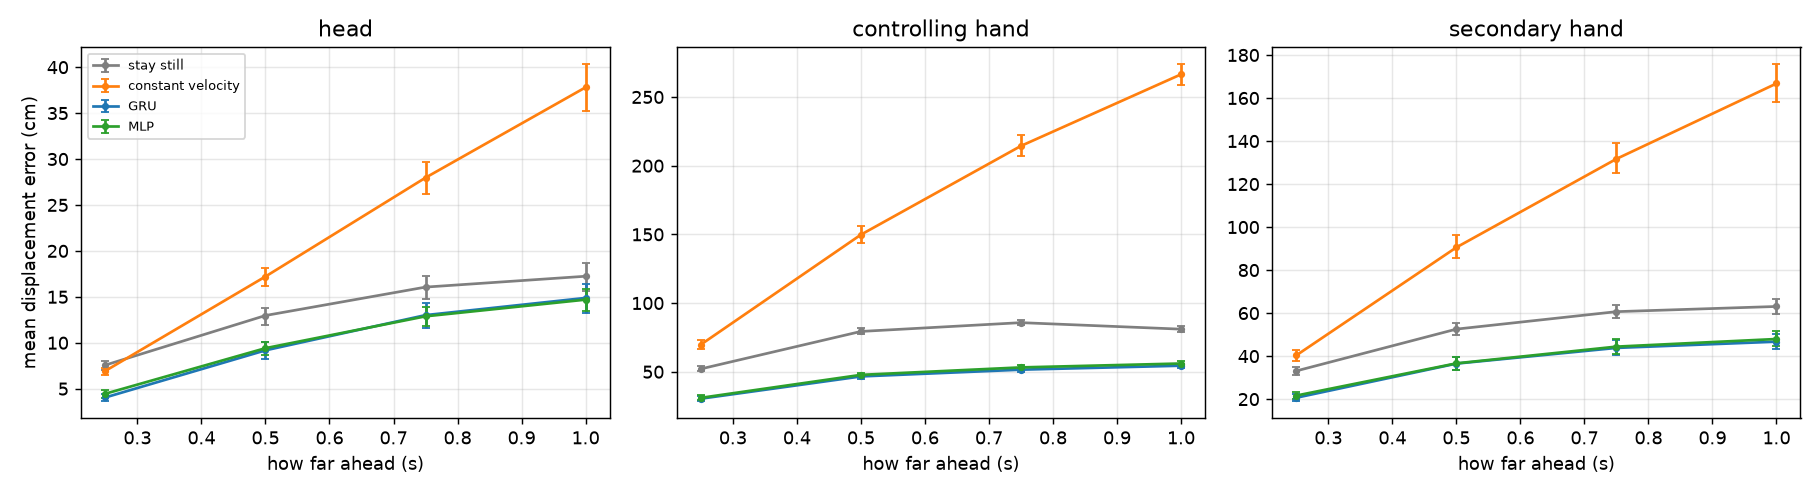

In [4]:
plot_error_by_horizon(tables, cfg, figures / "test_error_by_horizon.png")
from IPython.display import Image

Image(figures / "test_error_by_horizon.png")

### Do the models beat the baselines?
Constant velocity is worse than staying still. A likely reason is that strikes speed up and slow down quickly,
so continuing at the current velocity overshoots.

In [5]:
baseline = best_baseline(tables)
for name in ("GRU", "MLP"):
    gain = overall(tables[baseline]) - overall(tables[name])
    overlap = intervals_overlap(tables[name], tables[baseline])
    print(f"{name}: {overall(tables[name]):.1f} cm vs {baseline} {overall(tables[baseline]):.1f} cm "
          f"({gain:+.1f} cm, {gain / overall(tables[baseline]) * 100:+.0f}%). The 95% intervals {'overlap' if overlap else 'do not overlap'}.")
print("\nconstant velocity is worse than staying still:", overall(tables["constant velocity"]) > overall(tables["stay still"]))

GRU: 31.0 cm vs stay still 46.8 cm (+15.8 cm, +34%). The 95% intervals do not overlap.
MLP: 31.7 cm vs stay still 46.8 cm (+15.1 cm, +32%). The 95% intervals do not overlap.

constant velocity is worse than staying still: True


### Six predicted against true trajectories
Lines show the last second of movement. Filled markers are where the points really went, open markers are the predictions.

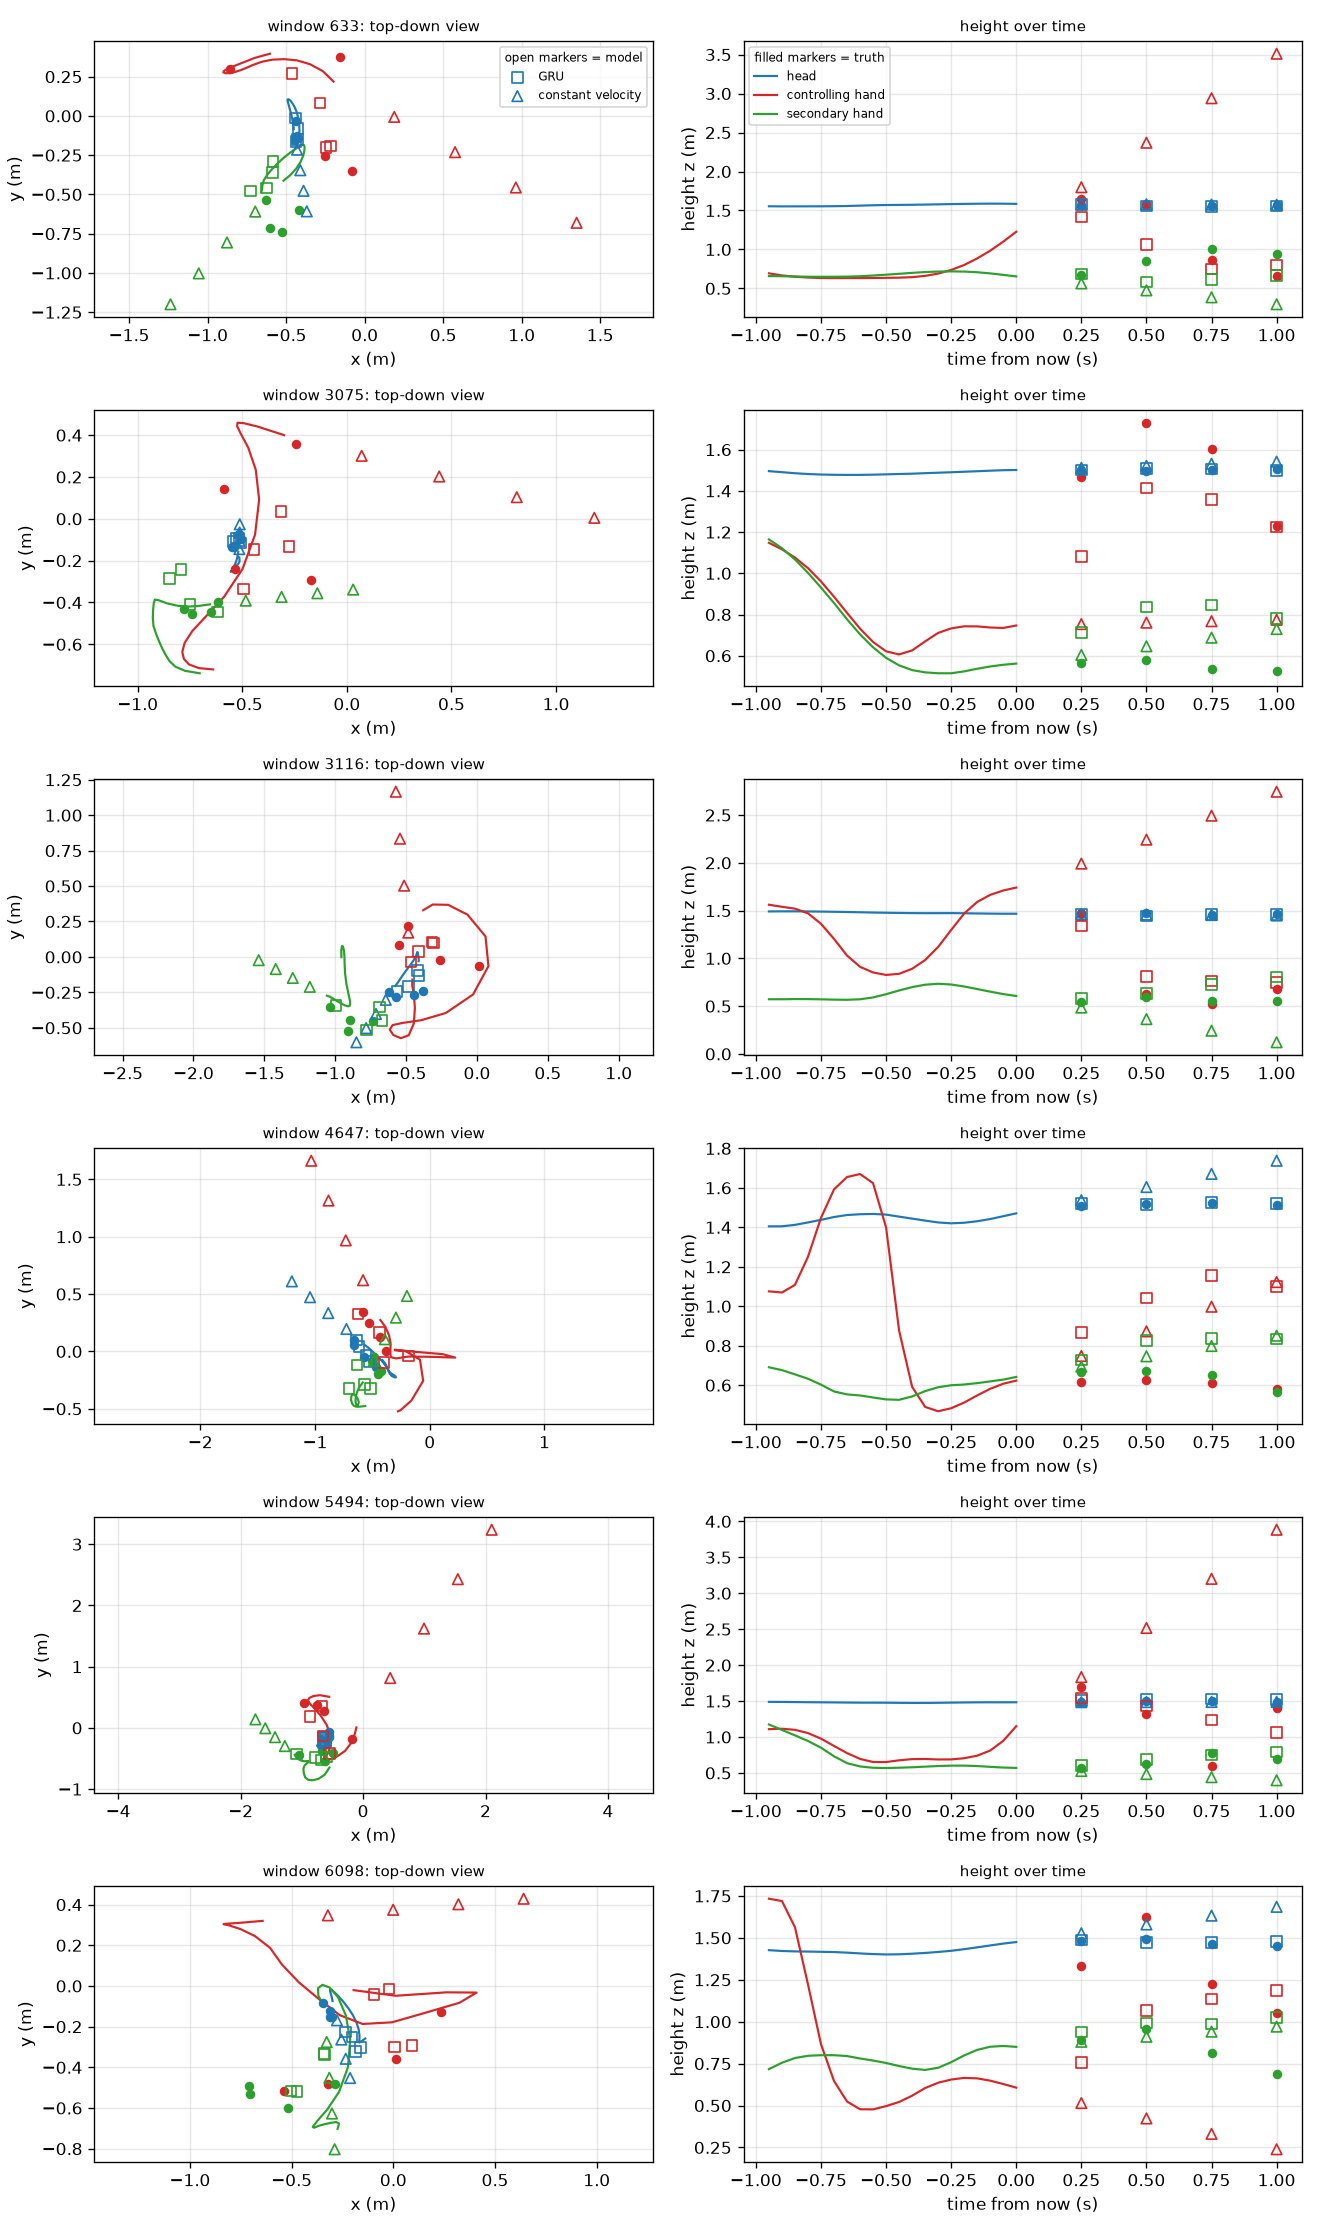

In [6]:
picks = pick_windows(len(true), 6, cfg["seed"])
plot_trajectories(raw, true, {"GRU": offsets["GRU"], "constant velocity": offsets["constant velocity"]}, picks, cfg, figures / "trajectories.png")
Image(figures / "trajectories.png")

## Step 9: train the final model on all recordings
The model type is chosen by the **validation** loss of the folds (not the test error, which must stay untouched).
The final model is trained again on all recordings for the median best epoch of the folds. It has no data of its own to stop on or to test on,
so the error numbers above describe the cross-validation models, not this exact file.

In [7]:
summary = pd.read_csv(reports / "training_summary.csv")
print("average validation loss per model:", summary.groupby("model").best_val_loss.mean().round(4).to_dict())
kind, epochs = pick_final_model(summary)
print(f"chosen: {kind.upper()}, trained for {epochs} epochs")

best_on_test = min(("GRU", "MLP"), key=lambda name: overall(tables[name]))
if best_on_test.lower() != kind:
    print(f"note: {best_on_test} has the lowest test error, which differs from the choice by validation loss. The choice by validation loss is kept.")

device = pick_device()
model, norm, history = final_refit(kind, cfg, windows, files, epochs, device, progress=False)
model = model.cpu().eval()
print(f"trained {history.epochs_run} epochs in {history.seconds:.1f} s on {history.device}, final training loss {history.train_loss[-1]:.4f}")
save_final_files(model, norm, cfg, models_dir, kind, epochs, files)

average validation loss per model: {'gru': 0.2015, 'mlp': 0.2096}
chosen: GRU, trained for 16 epochs


trained 16 epochs in 2.9 s on mps, final training loss 0.1424


### Export to ONNX and check it
The ONNX output must match the PyTorch output (allowed difference: `export.parity_tolerance`).

In [8]:
onnx_path = export_onnx(model, cfg, models_dir / cfg["export"]["onnx_file"])
print(f"saved {onnx_path.name} ({onnx_path.stat().st_size / 1024:.1f} kB)")
print("shapes:", onnx_io_shapes(onnx_path))
print("operators:", onnx_ops(onnx_path))

all_windows = stack(windows, files)
chosen = np.random.default_rng(cfg["seed"]).choice(len(all_windows["x"]), 20, replace=False)
difference = parity(model, onnx_path, norm_x(all_windows["x"][chosen], norm))
print(f"largest difference between PyTorch and ONNX on 20 random windows: {difference:.2e}")
assert difference < cfg["export"]["parity_tolerance"], "the ONNX model does not match the PyTorch model"

saved motion_forecaster.onnx (153.7 kB)
shapes: {'inputs': {'window': [1, 20, 22]}, 'outputs': {'offsets': [1, 36]}, 'opset': [15]}
operators: {'Add': 101, 'Constant': 522, 'Gather': 20, 'Gemm': 1, 'MatMul': 21, 'Mul': 60, 'Sigmoid': 40, 'Slice': 120, 'Sub': 20, 'Tanh': 20}
largest difference between PyTorch and ONNX on 20 random windows: 4.77e-07


### Example for testing the Unity side
`golden_vector.json` holds one real window, its features and the output the exported model must return.

In [9]:
i = chosen[0]
golden = golden_vector(model, norm, all_windows["raw"][i], all_windows["x"][i], cfg, models_dir / cfg["export"]["golden_vector_file"], onnx_path)
first_row = np.array(golden["expected_offsets_m"]).reshape(len(horizons), 9)[0]
print("expected movement after 0.25 s (m), head / controlling hand / secondary hand, each x y z:\n", np.round(first_row, 3))
print("ONNX output equals the PyTorch output:", np.allclose(golden["onnx_output_normalised"], golden["expected_output_normalised"], atol=cfg["export"]["parity_tolerance"]))

expected movement after 0.25 s (m), head / controlling hand / secondary hand, each x y z:
 [ 0.043 -0.069 -0.026 -0.105  0.146  0.159 -0.051 -0.076  0.023]
ONNX output equals the PyTorch output: True


### Model card

In [10]:
verdict = verdict_text(kind.upper(), tables)
write_model_card(
    models_dir / cfg["export"]["model_card_file"],
    {
        "cfg": cfg,
        "results": results_summary(tables, [h / rate for h in horizons]),
        "verdict": verdict,
        "exported_kind": kind,
        "n_params": n_params(model),
        "opset": cfg["export"]["opset"],
        "n_files": len(files),
        "minutes": sum(s.frames for s in segments) / rate / 60,
        "n_windows": int(len(all_windows["x"])),
        "fold_sizes": [len(s.test) for s in splits],
        "final_epochs": epochs,
    },
)
print(verdict)
print("\nfiles in", models_dir)
for path in sorted(models_dir.iterdir()):
    print(" ", path.name)

**Does it beat the baselines?** The GRU has an overall error of 31.0 cm. The best baseline (stay still) has 46.8 cm. The model is better, and the 95% intervals do not overlap.

files in /Users/dikshanta/Documents/VR-Game/VR-Gamification-Fitness/ml-services/models
  cv_folds
  golden_vector.json
  model_card.md
  motion_forecaster.onnx
  motion_forecaster.pt
  norm.json
  training_config.yaml
